In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


In [2]:
df = pd.read_csv("/content/weatherHistory.csv")

In [3]:
df.drop(columns=["Formatted Date"], inplace=True)


In [4]:
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())


In [5]:
cat_cols = df.select_dtypes(include=["object", "string"]).columns
df[cat_cols] = df[cat_cols].apply(lambda x: x.fillna(x.mode()[0]))

In [6]:
def map_weather(summary):
    summary = summary.lower()
    if "rain" in summary:
        return "Rain"
    elif "snow" in summary:
        return "Snow"
    elif "fog" in summary:
        return "Fog"
    elif "wind" in summary:
        return "Windy"
    elif "storm" in summary or "thunder" in summary:
        return "Storm"
    elif "cloud" in summary:
        return "Cloudy"
    else:
        return "Clear"


In [7]:
df["Weather_Category"] = df["Daily Summary"].apply(map_weather)


In [8]:
category_counts = df["Weather_Category"].value_counts()

px.bar(
    category_counts,
    title="Weather Category Distribution",
    labels={"value": "Count", "index": "Weather Category"}
).show()

In [9]:
# Encode input categorical features
for col in ["Summary", "Precip Type"]:
    df[col] = LabelEncoder().fit_transform(df[col])

# Encode target
target_encoder = LabelEncoder()
df["Weather_Category"] = target_encoder.fit_transform(df["Weather_Category"])


In [10]:
X = df.drop(["Daily Summary", "Weather_Category"], axis=1)
y = df["Weather_Category"]


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [12]:
def evaluate_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"\n{name} Performance")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


Random Forest Performance
Accuracy: 0.8615934891918511
              precision    recall  f1-score   support

           0       0.75      0.15      0.24       936
           1       0.87      0.97      0.92     14466
           2       0.82      0.63      0.71      3808
           3       1.00      0.05      0.10        38
           4       0.00      0.00      0.00        43

    accuracy                           0.86     19291
   macro avg       0.69      0.36      0.40     19291
weighted avg       0.85      0.86      0.84     19291



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



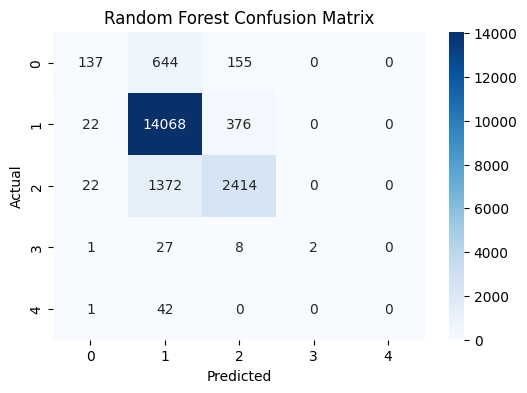

In [13]:
rf = RandomForestClassifier(
    n_estimators=120,
    max_depth=18,
    min_samples_leaf=10,
    n_jobs=-1,
    random_state=42
)

evaluate_model(rf, "Random Forest")



Gradient Boosting Performance
Accuracy: 0.8523663884713079
              precision    recall  f1-score   support

           0       0.51      0.11      0.18       936
           1       0.87      0.97      0.91     14466
           2       0.79      0.61      0.69      3808
           3       0.83      0.53      0.65        38
           4       0.40      0.14      0.21        43

    accuracy                           0.85     19291
   macro avg       0.68      0.47      0.53     19291
weighted avg       0.83      0.85      0.83     19291



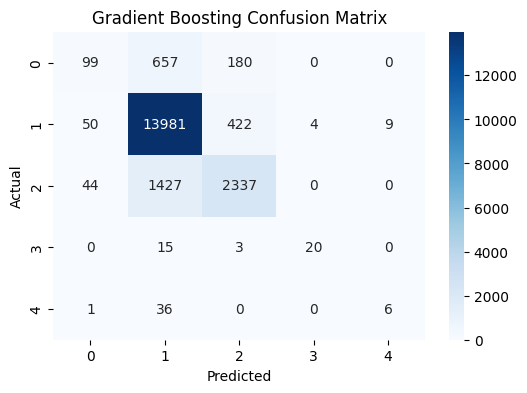

In [14]:
gb = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.1,
    random_state=42
)

evaluate_model(gb, "Gradient Boosting")


In [15]:
feature_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

px.bar(
    feature_importance,
    title="Feature Importance (Random Forest)"
).show()


In [16]:
model_scores = {
    "Random Forest": accuracy_score(y_test, rf.predict(X_test)),
    "Gradient Boosting": accuracy_score(y_test, gb.predict(X_test))
}

score_df = pd.DataFrame.from_dict(
    model_scores,
    orient="index",
    columns=["Accuracy"]
)

px.bar(score_df, title="Model Accuracy Comparison").show()


"""
Conclusion:
- Direct classification of raw weather summaries resulted in poor performance
  due to high class cardinality and imbalance.
- Reformulating the problem into meaningful weather categories significantly
  improved accuracy, interpretability, and business usefulness.
- Random Forest performed best due to robustness and explainability.

Recommendation:
Deploy Random Forest for weather category classification to support
forecasting insights and operational planning.
"""
